# $Rocio  Argote$

### 22.373.783-8

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
rng = np.random.default_rng(seed=33591)

## Ejercicio 1

In [39]:
#arreglo temporal
tiempo = np.linspace(0, 10, 500) # empieza desde 0 años hasta 10 años, y 500 cantidad de mediciones

In [40]:
flujo = np.ones(len(tiempo)) #se busca que cada valor dentro de la variable tiempo sea de 1

ruido = rng.normal(loc=0, scale=0.002, size=len(tiempo)) #se usa rng.normal ya que previamente se definio, se omite uso de np.random.normal()

# loc= 0 equivale a una media del ruido gaussiano igual a 0
# scale= 0.002 equivale a la deviacion estandar del ruido
# size= len(tiempo) es el tamaño del ruido, o sea las 500 mediciones equidistantes

flujo = flujo + ruido #lo reescribo sumandole el ruido gaussiano


In [41]:
#generar simulaciones de dos transitos 
transito1 = (tiempo >= 4.5) & (tiempo <= 5.0) #usamos esos valores para tener un intervalor mas pequeño
transito2 = (tiempo >= 7.0) & (tiempo <= 7.4)

#reduzco el flujo durante cada transito
flujo[transito1] = flujo[transito1] - 0.02 
flujo[transito2] = flujo[transito2]- 0.015

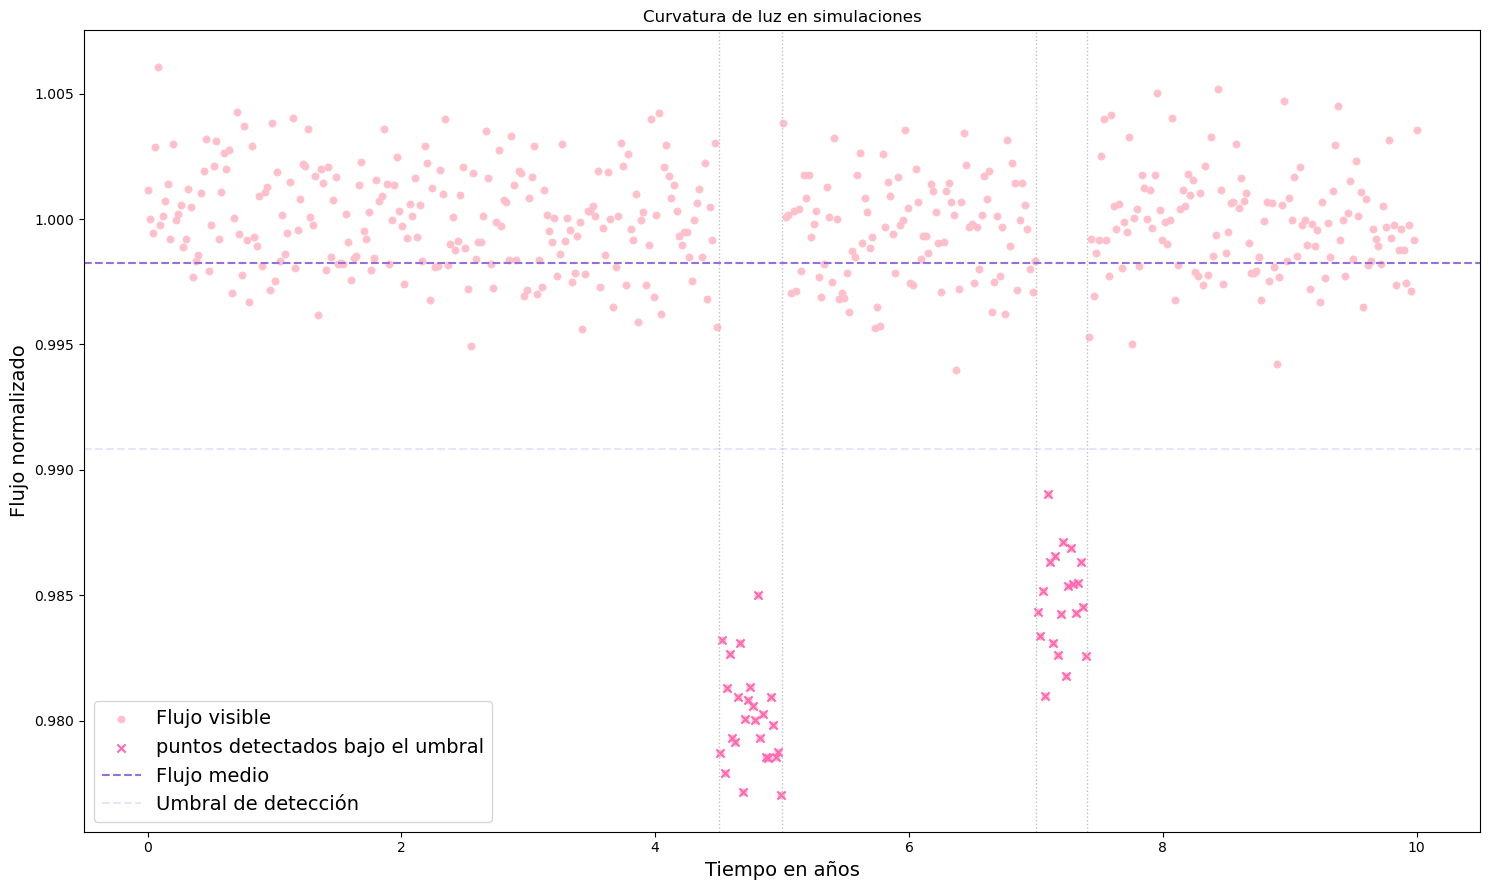

Flujo medio: 0.9982695620530542
Umbral de detección: 0.9922695620530542
Cantidad de puntos bajo el umbral: 45


In [55]:
def grafica_curva_de_luz(tiempo, flujo):
    
#calculo el flujo medio
    flujo_medio = np.mean(flujo) #np.mean() se usa para sacar el promedio a cierto valor

    
#su desviacion estandar
    desviacion = 0.002

    
#umbral de deteccion:
    umbral_deteccion = flujo_medio - 3 * desviacion

    
#puntos que están bajo el umbral
    puntos_detectados = flujo < umbral_deteccion

    
    plt.figure(figsize=(15, 9)) #plt.figure() se usa para crear una figura, 15 es el ancho y 9 el alto que escogi para la figura.
    plt.scatter(tiempo, flujo, color="pink" , s=22, label="Flujo visible") #plt.scatter dibuja los puntos
    #flujo que cumple la condicion:
    plt.scatter(tiempo[puntos_detectados], flujo[puntos_detectados], color="hotpink", marker="x", s=35, label="puntos detectados bajo el umbral")

    
    #lineas horizontales para el flujo medio y el umbral
    plt.axhline(flujo_medio, color="mediumpurple", linestyle="--", label="Flujo medio")
    plt.axhline(umbral, color="lavender", linestyle="--", label="Umbral de detección")

    #lineas verticales que marcan el inicio y el fin de cada tránsito.
    for limite in [4.5, 5.0, 7.0, 7.4]:
        plt.axvline(limite, color="silver", linestyle=":", linewidth=1)

    plt.xlabel("Tiempo en años", fontsize=14)
    plt.ylabel("Flujo normalizado", fontsize=14)
    plt.title("Curvatura de luz en simulaciones")
    plt.legend(fontsize=14)
    plt.tight_layout()
    plt.show()

    return flujo_medio, umbral_deteccion, np.sum(puntos_detectados)
grafico = grafica_curva_de_luz(tiempo, flujo)
print("Flujo medio:", flujo_medio)
print("Umbral de detección:", umbral_deteccion)
print("Cantidad de puntos bajo el umbral:", cantidad_detectada)

## Ejercicio 2

In [77]:
#condiciones iniciales:
I0 = 100
sigma = 0.5
N_estrellas = 5

#posiciones aleatorias de las cinco estrellas
x0 = rng.uniform(-5, 5, N_estrellas) #rng.uniform se usa para generar numeros aleatorias con distribucion uniforme
y0 = rng.uniform(-5, 5, N_estrellas) #el 1er valor es el limite inferior, el 2do limite superior, el 3ro, cantidad de numeros a generar

#coordenadas físicas de -5 a 5 en ambos ejes
x = np.linspace(-5, 5, 300)
y = np.linspace(-5, 5, 300)

#x e y son matrices con las coordenadas de cada pixel
X, Y = np.meshgrid(x, y) #np.meshgrid combina 2 ejes para formar un "mapa" de coordenadas

In [81]:
#creola cuadrícula de coordenadas
X, Y = np.meshgrid(x, y)

#creo la matriz bidimensional de intensidad
intensidad = np.zeros(X.shape)

#creo la luz de cada estrella
for i in range(N_estrellas):

    #distancias desde cada píxel al centro de la estrella
    dx = X - x0[i]
    dy = Y - y0[i]

    #intensidad de la estrella
    intensidad_estrella = I0 * np.exp(
        -(dx**2 + dy**2) / (2 * sigma**2)
    )

    #sumola luz a la matriz
    intensidad = intensidad + intensidad_estrella

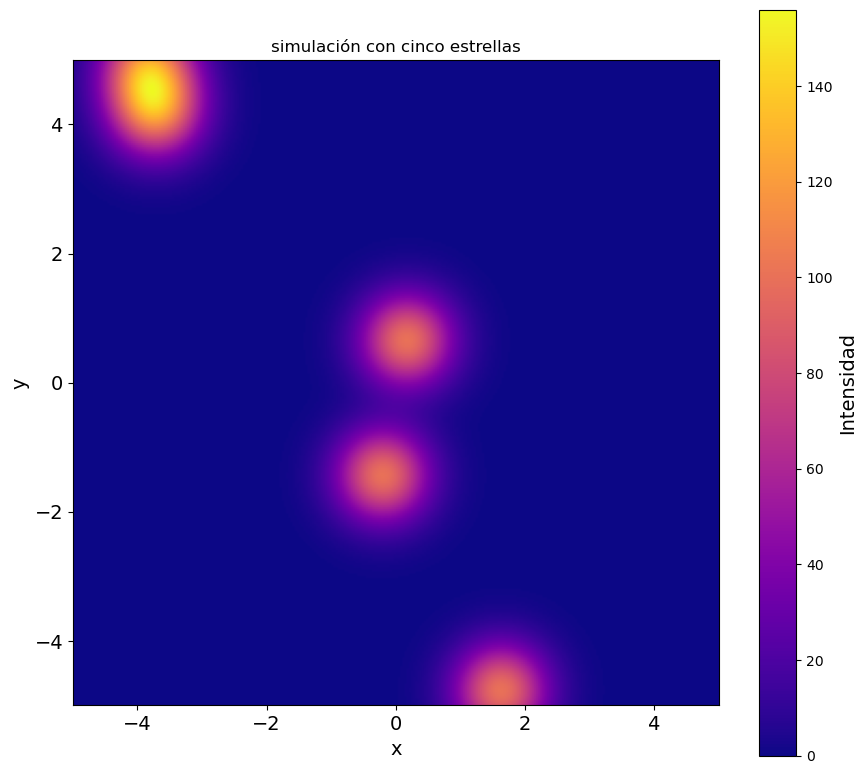

In [82]:
plt.figure(figsize=(9, 8)) #creo una figura
plt.imshow(intensidad, origin="lower", extent=[-5, 5, -5, 5], cmap="plasma", aspect="equal") #plt.imshow muestra una matriz como imagen usando colores
# barra de colores 
barra = plt.colorbar() 
barra.set_label("Intensidad", fontsize=14)
#ejes
plt.xlabel("x", fontsize=14)
plt.ylabel("y", fontsize=14)

plt.title("simulación con cinco estrellas") #titulo
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.show()

In [83]:
#creo una función que recibe las coordenadas x0 e y0 de los centros de las estrellas
def calcular_distancias(x0, y0):

    #len(x0) dice cuántas estrellas tenemos, como tenemos 5 estrellas, tendremos 5 filas y 5 columnasen nuestra matriz de distancias
    N = len(x0)

    #creo una matriz llena de ceros, cada posición guardará la distancia entre dos estrellas
    distancias = np.zeros((N, N))

    #recorremos las estrellas usando sus posiciones i representa la primera estrella
    for i in range(N):

        #j representa la segunda estrella
        for j in range(N):

            #calculo cuanto se diferencian sus coordenadas en x
            dx = x0[i] - x0[j]

            #calculo cuanto se diferencian sus coordenadas en y
            dy = y0[i] - y0[j]
            #aplico el teorema de Pitagoras para calcular la distancia entre los dos centros
            distancia = np.sqrt(dx**2 + dy**2)

            #guardo los datos
            distancias[i, j] = distancia

    #devuelvo la matriz completa de distancias
    return distancias


#llamo a la función
distancias = calcular_distancias(x0, y0)

#muestro la matriz en pantalla
print("Matriz de distancias entre las estrellas:")
print(distancias)

Matriz de distancias entre las estrellas:
[[ 0.          3.81364275  5.63189379 10.46103498 11.12379295]
 [ 3.81364275  0.          2.13039131  6.65111278  7.31063648]
 [ 5.63189379  2.13039131  0.          5.26870162  5.84397257]
 [10.46103498  6.65111278  5.26870162  0.          0.70496173]
 [11.12379295  7.31063648  5.84397257  0.70496173  0.        ]]


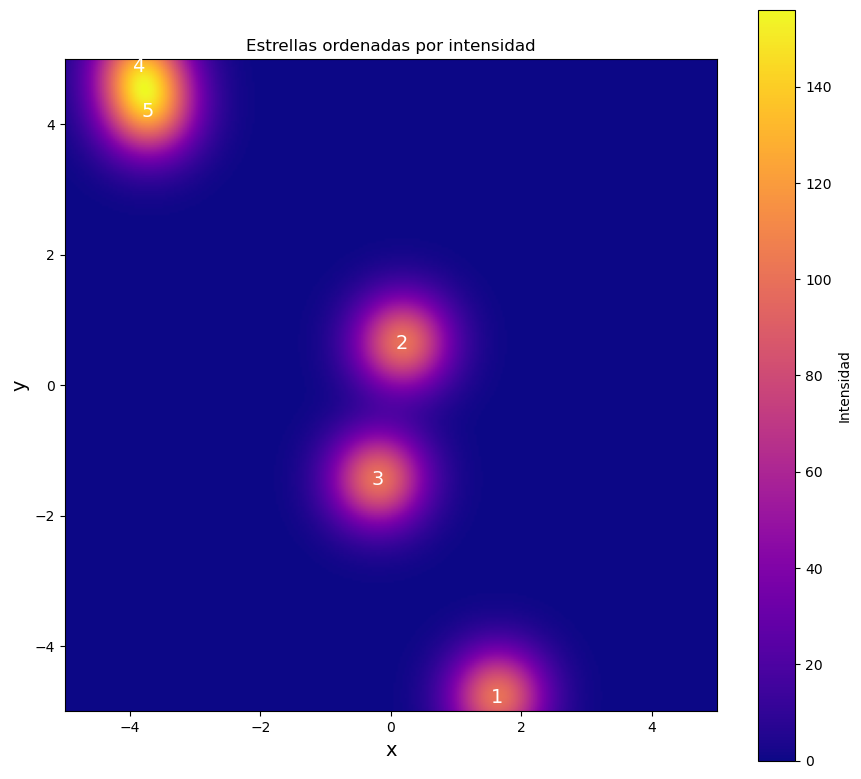

In [84]:
#creo un arreglo para guardar la intensidad del pixel mas cercano al centro de cada estrella
intensidad_centros = np.zeros(N_estrellas)

#recorro las cinco estrellas
for i in range(N_estrellas):

    #busco la posicion del pixel mas cercano en x
    ix = np.argmin(np.abs(x - x0[i]))

    #busco la posicion del pixel mas cercano en y
    iy = np.argmin(np.abs(y - y0[i]))

    #guardo la intensidad de ese pixel
    intensidad_centros[i] = intensidad[iy, ix]

#ordeno las estrellas de menor a mayor intensidad
orden = np.argsort(intensidad_centros)

#creola figura
plt.figure(figsize=(9, 8))

#muestro la imagen
plt.imshow(intensidad, origin="lower", extent=[-5, 5, -5, 5], cmap="plasma", aspect="equal")

#numero las estrellas segun el orden obtenido
for i in range(N_estrellas):

    #selecciono la estrella correspondiente
    estrella = orden[i]

    #escribo su numero en el centro
    plt.text(x0[estrella], y0[estrella], str(i + 1), color="white", fontsize=14, ha="center", va="center")
    
#barra de colores, título, etc
plt.xlabel("x", fontsize=14)
plt.ylabel("y", fontsize=14)
plt.colorbar(label="Intensidad")
plt.title("Estrellas ordenadas por intensidad")
plt.tight_layout()
plt.show()

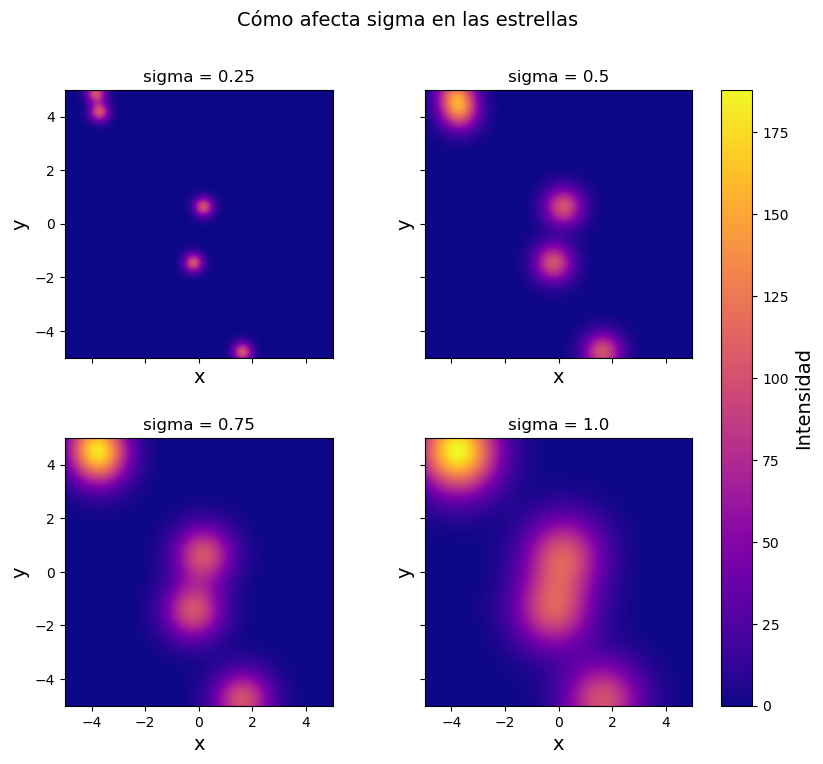

In [88]:
#valores de sigma que vamos a comparar
valores_sigma = [0.25, 0.5, 0.75, 1.0]

#creo cuatro gráficos organizados en 2 filas y 2 columnas, sharex y sharey permiten compartir los ejes
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

#creo una lista para guardar las cuatro imágenes
imagenes = []

#repito el cálculo usando cada valor de sigma
for s in valores_sigma:

    # Creamos una matriz de intensidad que comienza en cero
    intensidad_s = np.zeros(X.shape)

    #recorro las cinco estrellas
    for i in range(N_estrellas):

        #distancias desde cada pixel al centro de la estrella
        dx = X - x0[i]
        dy = Y - y0[i]

        #calculo la luz usando el sigma actual
        luz = I0 * np.exp(-(dx**2 + dy**2) / (2 * s**2))

        #sumo la luz de esta estrella
        intensidad_s = intensidad_s + luz

    #guardo la imagen calculada
    imagenes.append(intensidad_s)

#busco la mayor intensidad de las cuatro imágenes
max_intensidad = max(np.max(img) for img in imagenes)

#ciclo for para los cuatro gráficos
for i, ax in enumerate(axes.flat):

    #muestro una imagen en cada gráfico
    imagen = ax.imshow(imagenes[i], origin="lower", extent=[-5, 5, -5, 5], cmap="plasma", aspect="equal", vmin=0, vmax=max_intensidad)

    #valores de sigma
    ax.set_title(f"sigma = {valores_sigma[i]}")

    #etiquetas
    ax.set_xlabel("x", fontsize=14)
    ax.set_ylabel("y", fontsize=14)

#creo una única barra de colores para las cuatro imágenes
fig.subplots_adjust(right=0.85, top=0.88, hspace=0.3, wspace=0.2)

#creo una única barra de colores a la derecha
barra = fig.colorbar(imagen, ax=axes.ravel().tolist(), location="right", fraction=0.05, pad=0.04)

#nombre de la barra de colores
barra.set_label("Intensidad", fontsize=14)

#titull
fig.suptitle("Cómo afecta sigma en las estrellas",fontsize=14)
plt.show()